**Table of contents**<a id='toc0_'></a>    
- [Introdução](#toc1_)    
- [Modelo matemático](#toc2_)    
  - [Dinâmica não linear com variável de agendamento](#toc2_1_)    
  - [Linearização em pontos de uma grade fina de operação](#toc2_2_)    
  - [Controladores locais como problemas de otimização](#toc2_3_)    
  - [Ajuste de leis de ganho via mínimos quadrados](#toc2_4_)    
- [Solução computacional](#toc3_)    
  - [Modelo não linear do tanque](#toc3_1_)    
  - [Cálculo de pontos de operação e linearização](#toc3_2_)    
  - [Síntese de controladores locais por LQR](#toc3_3_)    
  - [Ajuste da lei de ganhos $K(\rho)$ por mínimos quadrados regularizado](#toc3_4_)    
  - [Resultados numéricos da otimização](#toc3_5_)    
  - [Seleção automática de pontos de operação](#toc3_6_)    
    - [Resultados numéricos da seleção automática](#toc3_6_1_)    
- [Discussão](#toc4_)    
  - [Limitações do modelo e da linearização](#toc4_1_)    
  - [Escolha dos pesos e da regularização](#toc4_2_)    
  - [Casos especiais e situações críticas](#toc4_3_)    
  - [Generalizações dentro da mesma estrutura](#toc4_4_)    
  - [Comparação numérica entre as leis de ganho e solvers utilizados](#toc4_5_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# <a id='toc1_'></a>[Introdução](#toc0_)

Em muitos sistemas, como veículos, processos industriais, motores elétricos e sistemas aeroespaciais, o comportamento dinâmico muda de forma perceptível com o <span style="color:#64B5F6;">ponto de operação</span>: alterações de carga, velocidade, nível ou temperatura podem modificar de forma significativa a resposta da planta. Quando se utiliza um único conjunto de parâmetros de controle ajustado em torno de uma condição específica, é comum que o desempenho piore à medida que o sistema se afasta dessa condição.

Para lidar com essa variação, foi desenvolvida a ideia de <span style="color:#64B5F6;">controle por agendamento de ganhos</span> (*gain scheduling*). Nesse tipo de estratégia, os parâmetros do controlador são ajustados em função de uma <span style="color:#64B5F6;">variável de agendamento</span> $ \rho $ (por exemplo, altitude em aeronaves, abertura de válvula em processos de fluxo ou regime de carga em motores). Esse conceito foi explorado inicialmente em aplicações aeronáuticas e em turbomáquinas e, posteriormente, formalizado no contexto de sistemas LPV (*Linear Parameter-Varying*), tornando-se uma ferramenta consolidada em controle moderno [2]. Quando os ganhos variam de forma contínua com $ \rho $, a transição entre diferentes condições operacionais tende a ser mais suave e previsível.

Grande parte das aplicações práticas de *gain scheduling* segue uma lógica em duas etapas: (i) escolher manualmente alguns pontos de operação $ \rho_i $ em uma faixa de interesse e projetar, em cada um deles, um controlador local “ótimo”; (ii) conectar esses controladores por meio de uma lei contínua de ganhos $ K(\rho) $, usualmente obtida por interpolações ad hoc ou ajustes por mínimos quadrados. Nessa abordagem, o número de pontos de operação e sua localização são definidos pelo projetista com base em experiência, o que pode levar tanto a malhas excessivamente densas (complexidade desnecessária) quanto a malhas pobres (perda de desempenho em certas regiões).

Neste trabalho, o foco é investigar como ferramentas de <span style="color:#FFB74D;">otimização convexa</span> e de <span style="color:#FFB74D;">modelagem em grafos</span> podem ser utilizadas para <span style="color:#64B5F6;">automatizar</span> essa escolha. A ideia central é a seguinte:

- primeiro, considera-se uma <span style="color:#64B5F6;">grade fina</span> de pontos na faixa de operação da variável de agendamento $ \rho $; em cada ponto, projeta-se um ganho local $ K^\star(\rho) $ a partir de problemas de <span style="color:#FFB74D;">otimização quadrática</span> (como LQR em horizonte finito e QPs clássicos) [3, 5];  
- em seguida, modela-se o problema de “conectar” esses ganhos em uma lei de agendamento $ K(\rho) $ como um problema de <span style="color:#FFB74D;">mínimos quadrados com regularização</span> [3, 4, 10];  
- finalmente, utiliza-se uma formulação inspirada em <span style="color:#FFB74D;">problemas de fluxo em redes e caminhos mínimos</span> [6, 7] para selecionar, de forma sistemática, um <span style="color:#64B5F6;">subconjunto mínimo de pontos de operação</span> (e, portanto, de ganhos distintos) capaz de manter o erro de aproximação abaixo de um limite especificado.

Dessa forma, em vez de fixar a priori o número de pontos de operação, o projetista fornece apenas: (i) a <span style="color:#64B5F6;">faixa de operação</span> em $ \rho $ e (ii) um <span style="color:#64B5F6;">critério de desempenho</span> (por exemplo, erro máximo admissível entre o ganho agendado $ K(\rho) $ e o ganho local “ideal” $ K^\star(\rho) $). O número de ganhos, bem como suas posições na faixa de operação, passam a ser resultado de um problema de otimização, combinando técnicas de <span style="color:#FFB74D;">least squares regularizado</span>, <span style="color:#FFB74D;">programação quadrática</span> e <span style="color:#FFB74D;">modelos de caminho mínimo em grafos</span>.

Essa abordagem será explorada, ao longo do trabalho, em um exemplo de tanque de nível com saída por gravidade, permitindo ilustrar a interface entre <span style="color:#64B5F6;">controle por agendamento de ganhos</span> e os principais conceitos de <span style="color:#FFB74D;">programação convexa e combinatória</span> apresentados em disciplina, como mínimos quadrados, QPs e problemas de fluxo/caminho mínimo em redes.

<span style="color:#B0BEC5;"><em>Referências básicas</em></span>  
- [1] Boyd, S., & Vandenberghe, L. (2004). <em>Convex Optimization</em>. Cambridge University Press.  
- [2] Apkarian, P., Gahinet, P., & Becker, G. (1995). <em>LPV Control and Gain Scheduling</em>. IEEE Trans. Automatic Control, 40(11), 1826–1840.  
- [3] “Least Squares (Slide 8)”, notas de aula de COS360 / COM361, 2025/2.  
- [4] “Equality Constraints and Tradeoffs (Slide 9)”, notas de aula de COS360 / COM361, 2025/2.  
- [5] “QPs and QCQPs (Slide 12)”, notas de aula de COS360 / COM361, 2025/2.  
- [6] “Network Flow Problems (Slide 5)”, notas de aula de COS360 / COM361, 2025/2.  
- [7] “Dual Flow Algorithms (Slide 7)”, notas de aula de COS360 / COM361, 2025/2.  
- [10] “Regularization (Slide 10)”, notas de aula de COS360 / COM361, 2025/2.  


# <a id='toc2_'></a>[Modelo matemático](#toc0_)

Nesta seção, o problema de agendamento contínuo de ganhos é escrito em termos de um modelo dinâmico e de problemas de otimização. A ideia é partir de uma dinâmica não linear dependente de uma variável de agendamento $ \rho $, obter modelos lineares locais em uma grade fina de operação e, a partir deles, construir ganhos locais ideais $ K^\star(\rho_k) $ que servirão de base para a etapa posterior de seleção ótima de pontos de operação.

## <a id='toc2_1_'></a>[Dinâmica não linear com variável de agendamento](#toc0_)

Considera-se um sistema SISO, com dinâmica não linear dependente de uma variável de agendamento $ \rho $:

- estado: $ x(t) \in \mathbb{R}^n $  
- entrada de controle: $ u(t) \in \mathbb{R} $  
- saída medida: $ y(t) \in \mathbb{R} $  
- variável de agendamento: $ \rho \in \mathbb{R} $ (escalar)

A evolução do sistema é descrita por
$$
\dot{x}(t) = f(x(t), u(t), \rho), \qquad y(t) = g(x(t), u(t), \rho).
$$

A variável $ \rho $ representa o ponto de operação (por exemplo, nível de tanque, condição de carga ou faixa de velocidade) e será usada para definir uma lei de controle $ K(\rho) $ a partir de ganhos locais ideais $ K^\star(\rho_k) $, calculados em uma grade fina de valores $ \rho_k $ na faixa de interesse.

Do ponto de vista de otimização, essa descrição fornece:

- as restrições de igualdade (dinâmica do sistema), que aparecem nos problemas de projeto de controladores locais em forma de problemas quadráticos;  
- a base para formular problemas de least squares quando se ajusta uma lei $ K(\rho) $ a partir de valores discretos $ K^\star(\rho_k) $;  
- a estrutura típica de problemas de programação quadrática (QP) quando se consideram custos quadráticos e limitações em entradas e estados.

<div style="text-align:center; margin-top:10px; margin-bottom:10px;">
  <img src="./img/Figure_21.png" style="max-width:75%; border-radius:8px;">
  <div style="color:#B0BEC5; font-size:0.9em; margin-top:4px;">
    Figura 2.1 – Geometria de mínimos quadrados como projeção de dados em uma reta.
  </div>
</div>

## <a id='toc2_2_'></a>[Linearização em pontos de uma grade fina de operação](#toc0_)

Como o sistema é não linear, o comportamento exato depende de $ (x, u, \rho) $ de forma possivelmente complexa. Para aplicar as ferramentas de otimização convexa estudadas em disciplina, adota-se uma aproximação linear local em uma grade fina de valores da variável de agendamento.

Seja uma grade
$$
\rho_1, \rho_2, \dots, \rho_N
$$
cobrindo a faixa de operação de interesse. Para cada $ \rho_k $:

1. determina-se um ponto de equilíbrio $ (x_k^\star, u_k^\star) $ pela condição de regime permanente
   $$
   \dot{x} = 0 \quad \Longrightarrow \quad f(x_k^\star, u_k^\star, \rho_k) = 0;
   $$

2. define-se o desvio em relação ao equilíbrio:
   $$
   \tilde{x}(t) = x(t) - x_k^\star, \qquad \tilde{u}(t) = u(t) - u_k^\star;
   $$

3. aplica-se a expansão de primeira ordem de $ f $ em torno de $ (x_k^\star, u_k^\star, \rho_k) $, obtendo um modelo linear local:
   $$
   \dot{\tilde{x}}(t) \approx A_k \tilde{x}(t) + B_k \tilde{u}(t),
   $$
   em que
   $$
   A_k = \left.\frac{\partial f}{\partial x}\right|_{(x_k^\star,u_k^\star,\rho_k)}, \qquad
   B_k = \left.\frac{\partial f}{\partial u}\right|_{(x_k^\star,u_k^\star,\rho_k)}.
   $$

Na implementação numérica, os Jacobianos $ A_k $ e $ B_k $ são aproximados por diferenças finitas, a partir de chamadas à dinâmica $ f $. O resultado é uma família de modelos lineares indexada pela grade fina de agendamento:
$$
\dot{\tilde{x}}(t) = A_k \tilde{x}(t) + B_k \tilde{u}(t), \qquad k = 1, \dots, N.
$$

Esses modelos serão usados diretamente na síntese de controladores locais ideais $ K_k^\star $, calculados via problemas de otimização quadrática.

## <a id='toc2_3_'></a>[Controladores locais como problemas de otimização](#toc0_)

Para cada modelo linearizado $ (A_k, B_k) $ da grade fina, considera-se um controlador de realimentação de estados na forma
$$
\tilde{u}(t) = -K_k^\star \tilde{x}(t),
$$
em que $ K_k^\star $ é um ganho (ou vetor de ganhos) obtido como solução de um problema de otimização quadrática associado ao ponto de operação $ \rho_k $.

Duas formulações complementares são adotadas para caracterizar $ K_k^\star $:

1. Controle LQR (Linear Quadratic Regulator) em horizonte infinito  

   Conceitualmente, escolhe-se $ K_k^\star $ para minimizar um custo quadrático contínuo no tempo:
   $$
   J_k = \int_0^\infty \left( \tilde{x}(t)^\top Q \tilde{x}(t) + \tilde{u}(t)^\top R \tilde{u}(t) \right)\, dt,
   $$
   sujeito à dinâmica linear
   $$
   \dot{\tilde{x}}(t) = A_k \tilde{x}(t) + B_k \tilde{u}(t).
   $$
   Esse problema é um exemplo de otimização quadrática convexa em controle, cuja solução analítica leva à equação de Riccati e ao ganho ótimo $ K_k^\star $. No contexto deste trabalho, essa formulação fornece uma referência teórica para o ganho ideal em cada ponto da grade de $ \rho_k $.

2. Controle em horizonte finito via programação quadrática (QP)  

   Em uma formulação alternativa mais próxima dos QPs estudados em disciplina, discretiza-se o sistema linear em torno de $ \rho_k $:
   $$
   x_{j+1} = A_{d,k}\, x_j + B_{d,k}\, u_j,
   $$
   onde $ A_{d,k} $ e $ B_{d,k} $ são as matrizes discretizadas associadas a $ A_k $ e $ B_k $, e define-se um horizonte de controle $ N $. A variável de decisão passa a ser a sequência de comandos
   $$
   \mathbf{u} = [u_0, u_1, \dots, u_{N-1}]^\top.
   $$
   Considera-se então um custo do tipo
   $$
   J_k = \sum_{j=0}^{N-1} \left( x_j^\top Q x_j + u_j^\top R u_j \right) + x_N^\top Q_f x_N,
   $$
   sujeito à dinâmica discretizada e a restrições lineares em $ u_j $ e em $ \Delta u_j $ (por exemplo, limites de saturação e taxa de variação). Na forma matricial, esse problema assume o formato de um QP clássico:
   $$
   \min_{\mathbf{u}} \; \frac{1}{2}\,\mathbf{u}^\top H \mathbf{u} + f^\top \mathbf{u}
   \quad \text{sujeito a} \quad
   G \mathbf{u} \le h,
   $$
   com $ H \succeq 0 $. A solução fornece uma sequência ótima de comandos e, em certas configurações (por exemplo, horizonte recedente), permite extrair uma política de realimentação equivalente a um ganho $ K_k^\star $ no ponto $ \rho_k $.

Em ambos os casos, associa-se a cada ponto da grade fina $ \rho_k $ um ganho local ideal $ K_k^\star $, resultando em um conjunto denso de dados
$$
(\rho_1, K_1^\star), \; (\rho_2, K_2^\star), \; \dots, \; (\rho_N, K_N^\star),
$$
que será utilizado na etapa de construção e simplificação da lei de agendamento de ganhos.

<span style="color:#64B5F6;">Resumo de otimização local:</span>  

- Variável de decisão (LQR): ganho $ K_k^\star $ que define a lei de controle $ \tilde{u} = -K_k^\star \tilde{x} $.  
- Variável de decisão (QP): vetor de entradas $ \mathbf{u} = [u_0, \dots, u_{N-1}]^\top $.  
- Função objetivo: custo quadrático em estados e entradas $ J_k $.  
- Restrições: dinâmica linear (contínua ou discreta) e limites lineares em $ u_j $ e $ \Delta u_j $.  
- Método de solução: equação de Riccati (LQR) e solver de QP (por exemplo, OSQP) na formulação em horizonte finito.

<div style="text-align:center; margin-top:10px; margin-bottom:10px;">
  <img src="./img/Figure_22.png" style="max-width:75%; border-radius:8px;">
  <div style="color:#B0BEC5; font-size:0.9em; margin-top:4px;">
    Figura 2.2 – Exemplo geométrico de QP: curvas de nível quadráticas e região viável poligonal.
  </div>
</div>

## <a id='toc2_4_'></a>[Ajuste de leis de ganho via mínimos quadrados](#toc0_)

Uma vez calculados os ganhos locais ideais na grade fina, obtém-se um conjunto de dados
$$
(\rho_1, K_1^\star), \; (\rho_2, K_2^\star), \; \dots, \; (\rho_N, K_N^\star).
$$
A ideia é utilizar ferramentas de mínimos quadrados para modelar leis de agendamento de ganhos $ K(\rho) $ que aproximem esses valores de forma suave e estruturalmente simples.

Uma forma direta de fazer isso é assumir uma parametrização polinomial de baixo grau, por exemplo:
$$
K(\rho) = \theta_0 + \theta_1 \rho + \theta_2 \rho^2,
$$
em que os coeficientes $ \theta_j $ são desconhecidos. Para os $ N $ pontos da grade, define-se a matriz de regressão
$$
\Phi = 
\begin{bmatrix}
1 & \rho_1 & \rho_1^2 \\
1 & \rho_2 & \rho_2^2 \\
\vdots & \vdots & \vdots \\
1 & \rho_N & \rho_N^2
\end{bmatrix},
\quad
\theta =
\begin{bmatrix}
\theta_0 \\ \theta_1 \\ \theta_2
\end{bmatrix},
\quad
b =
\begin{bmatrix}
K_1^\star \\ K_2^\star \\ \vdots \\ K_N^\star
\end{bmatrix}.
$$

O ajuste de $ K(\rho) $ pode então ser formulado como um problema de  
<span style="color:#FFB74D;">mínimos quadrados com regularização</span>:
$$
\min_{\theta} \; \lVert \Phi \theta - b \rVert_2^2 + \gamma \lVert \theta \rVert_2^2,
$$
em que $ \gamma \ge 0 $ controla o compromisso entre ajuste aos dados locais (primeiro termo) e suavidade/norma dos parâmetros (segundo termo). Em termos geométricos, o primeiro termo corresponde à distância entre o vetor de dados $ b $ e o subespaço gerado pelas colunas de $ \Phi $, enquanto o segundo termo puxa a solução em direção à origem no espaço de parâmetros, evitando curvas excessivamente oscilatórias.

Para ganhos vetoriais (por exemplo, sistemas de ordem maior), cada componente de $ K(\rho) $ pode ser ajustada de forma análoga, compondo um problema de least squares regularizado por componente. Além disso, a estrutura de mínimos quadrados regularizados será reutilizada, em seções posteriores, na análise do erro de aproximação ao longo da faixa de $ \rho $, servindo de base para a formulação do problema de seleção ótima de pontos de operação em termos de caminhos mínimos em grafos.

<span style="color:#64B5F6;">Resumo de otimização em</span> $K(\rho)$<span style="color:#64B5F6;">:</span>  

- Variável de decisão: vetor de parâmetros $ \theta $ da lei de ganho $ K(\rho) $.  
- Função objetivo: erro quadrático entre $ K(\rho_k;\theta) $ e os ganhos locais ideais $ K_k^\star $, com termo de regularização $ \gamma \lVert \theta \rVert_2^2 $.  
- Restrições: nenhuma restrição explícita em $ \theta $ (problema LS regularizado, convexo).  
- Método de solução: sistema normal regularizado (equações normais) ou solver de QP equivalente.

<div style="text-align:center; margin-top:10px; margin-bottom:10px;">
  <img src="./img/Figure_23.png" style="max-width:75%; border-radius:8px;">
  <div style="color:#B0BEC5; font-size:0.9em; margin-top:4px;">
    Figura 2.3 – Ajuste de $K(\rho)$: pontos discretos $K_k^\star$ e curvas com regularização fraca e forte (efeito de $\gamma$).
  </div>
</div>



# <a id='toc3_'></a>[Solução computacional](#toc0_)

Esta seção apresenta a implementação computacional do problema de agendamento contínuo de ganhos. O objetivo é mostrar, passo a passo, como os problemas de otimização descritos na Seção 2 são resolvidos na prática, quais são as variáveis de decisão, funções objetivo, restrições e solvers utilizados.

A solução é estruturada em quatro etapas principais:

1. definição do modelo não linear do tanque e cálculo de pontos de equilíbrio em uma grade fina de $ \rho $;  
2. linearização e obtenção de modelos locais $ (A_k, B_k) $ em cada ponto da grade;  
3. síntese de controladores locais ideais por um método de otimização quadrática (LQR);  
4. ajuste de uma lei de ganhos $ K(\rho) $ por mínimos quadrados regularizado, utilizando um solver de otimização convexa.

Como caso base, utiliza-se um sistema de tanque de nível não linear com saída por gravidade, mas o mesmo código pode ser reutilizado, com poucas alterações, para outras plantas.

<span style="color:#64B5F6;">Parâmetros de configuração expostos no código:</span>  

- faixa de operação em $ \rho $: intervalo geral $ [\rho_{\min}, \rho_{\max}] $;  
- número de pontos da grade fina: $ N_{\rho} $;  
- vazão de entrada de referência para cálculo de equilíbrio: $ u_{\text{eq}} $;  
- pesos do LQR: $ q $ (nível) e $ r $ (esforço de atuação);  
- grau do polinômio de $ K(\rho) $: $ d $;  
- parâmetro de regularização: $ \gamma $.  

Esses parâmetros aparecem reunidos em um único bloco no código, permitindo variar rapidamente a região de operação em $ \rho $ e a “agressividade” do controle e da regularização.


In [10]:
"""
Seção 3 – Solução computacional (parte geral)

Este bloco define:
- imports necessários;
- parâmetros físicos do tanque;
- parâmetros de configuração do estudo (faixa de ρ, N_ρ, pesos LQR, etc.).

A ideia é concentrar aqui tudo que normalmente será ajustado ao explorar
diferentes regiões de operação e diferentes políticas de controle.
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from scipy import linalg
import cvxpy as cp
import pandas as pd

# ---------------------------------------------------------------------------
# PARÂMETROS DE CONFIGURAÇÃO DO ESTUDO
# ---------------------------------------------------------------------------

# Faixa de operação da variável de agendamento ρ (ponto de operação)
# Pode ser qualquer intervalo real, por exemplo:
#   [0.0, 1.0], [2.0, 7.5], [-1.0, 3.0], etc.
RHO_MIN = 0.0      # menor valor de ρ considerado
RHO_MAX = 1.0      # maior valor de ρ considerado

# Número de pontos da grade fina em ρ (usada para calcular ganhos "ideais" K*_k)
N_RHO_FINE = 21    # pode aumentar para uma grade mais densa (ex.: 51, 101, ...)

# Vazão de entrada usada para definir os pontos de equilíbrio (u_eq)
U_EQ_GUESS = 0.5   # valor de referência de u para o qual se busca equilíbrio

# Pesos do LQR (penalização de desvio de nível e esforço de atuação)
Q_LEVEL = 1.0      # peso q em h^2 (nível)
R_EFFORT = 0.1     # peso r em u^2 (esforço de controle)

# Grau do polinômio que parametriza K(ρ)
POLY_DEGREE = 2    # usualmente 1 ou 2 já são suficientes para o exemplo

# Parâmetro de regularização (ridge) na estimação de θ em K(ρ)
GAMMA_REG = 1e-2   # γ = 0 -> sem regularização; γ maior -> mais suavidade

# Semente para reprodutibilidade (se houver etapas aleatórias em extensões)
RANDOM_SEED = 42

# ---------------------------------------------------------------------------
# PARÂMETROS FÍSICOS DO TANQUE
# ---------------------------------------------------------------------------

A_TANK = 1.0   # área da seção transversal do tanque [m^2]
G = 9.81       # gravidade [m/s^2]
A0 = 0.05      # área mínima do orifício [m^2]
A1 = 0.15      # área máxima do orifício [m^2]

# Configuração padrão de gráficos
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["font.size"] = 11

np.random.seed(RANDOM_SEED)


## <a id='toc3_1_'></a>[Modelo não linear do tanque](#toc0_)

O modelo usado como exemplo é um tanque de nível com saída por gravidade. O estado é o nível $ h(t) $, a entrada de controle $ u(t) $ é a vazão de entrada, e a área efetiva de saída depende da variável de agendamento $ \rho $:

$$
\dot{h}(t) = -\frac{a(\rho)}{A_{\text{tank}}} \sqrt{2 g\, h(t)} + \frac{1}{A_{\text{tank}}}\,u(t).
$$

Para uma faixa geral de operação em $ \rho $, representada por um intervalo $ [\rho_{\min}, \rho_{\max}] $, a área de saída é modelada como uma interpolação linear entre dois valores extremos $ a_0 $ e $ a_1 $. No código, isso é feito normalizando $ \rho $ para um parâmetro auxiliar

$$
\beta(\rho) = \frac{\rho - \rho_{\min}}{\rho_{\max} - \rho_{\min}},
$$

e definindo

$$
a(\rho) = a_0 + \beta(\rho)\,(a_1 - a_0),
$$

de modo que:
- quando $ \rho = \rho_{\min} $, tem-se $ a(\rho) = a_0 $;  
- quando $ \rho = \rho_{\max} $, tem-se $ a(\rho) = a_1 $;  
- entre esses extremos, $ a(\rho) $ varia de forma afim com $ \rho $.

Para cada valor fixo de $ \rho $, deseja-se um ponto de equilíbrio $ (h^\star, u^\star) $ tal que o nível permaneça constante:

$$
\dot{h} = 0 \quad \Longrightarrow \quad f(h^\star, u^\star, \rho) = 0.
$$

No código, fixa-se $ u^\star = u_{\text{eq}} $ (parâmetro configurável) e resolve-se numericamente a equação não linear

$$
f(h^\star, u_{\text{eq}}, \rho) = 0
$$

para encontrar o nível estacionário $ h^\star $. Essa rotina será chamada nos diferentes valores de $ \rho_k $ da grade fina.


In [11]:
# ---------------------------------------------------------------------------
# 3.1 – Modelo não linear do tanque e cálculo de equilíbrio
# ---------------------------------------------------------------------------

def a_rho(rho: float) -> float:
    """
    Calcula a área efetiva de saída a(ρ) para uma faixa geral [RHO_MIN, RHO_MAX].

    Em ρ = RHO_MIN  -> a(ρ) = A0
    Em ρ = RHO_MAX  -> a(ρ) = A1
    Entre esses valores, é feita uma interpolação linear.

    Isso permite alterar a faixa de operação em ρ apenas modificando
    RHO_MIN e RHO_MAX no bloco de configuração.
    """
    # Normaliza ρ para o intervalo [0, 1]
    beta = (rho - RHO_MIN) / (RHO_MAX - RHO_MIN)
    return A0 + beta * (A1 - A0)


def tank_dynamics(t: float, h: float, u: float, rho: float) -> float:
    """
    Dinâmica não linear do tanque:

        dh/dt = -(a(ρ)/A_TANK) * sqrt(2 * G * h) + (1/A_TANK) * u

    Parâmetros
    ----------
    t   : tempo (não usado explicitamente aqui, mas mantido
          por compatibilidade com integradores como solve_ivp).
    h   : nível atual do tanque.
    u   : vazão de entrada (entrada de controle).
    rho : variável de agendamento, que define a(ρ).

    Retorno
    -------
    dhdt : derivada do nível (taxa de variação dh/dt).
    """
    # Garante que o nível não fique negativo por erros numéricos
    h = max(h, 0.0)
    dhdt = -(a_rho(rho) / A_TANK) * np.sqrt(2.0 * G * h) + (1.0 / A_TANK) * u
    return dhdt


def tank_equilibrium(rho: float, u_eq: float = U_EQ_GUESS):
    """
    Encontra um ponto de equilíbrio (h*, u*) para um valor fixo de ρ,
    resolvendo dh/dt = 0 para o nível h*.

    Estratégia:
    - fixa u* = u_eq (informado na configuração);
    - resolve f(h) = dh/dt = 0 para encontrar h*.

    Parâmetros
    ----------
    rho  : valor fixo da variável de agendamento.
    u_eq : vazão de entrada para a qual se deseja um nível em regime permanente.

    Retorno
    -------
    h_star : nível de equilíbrio encontrado numericamente.
    u_star : vazão de equilíbrio (igual a u_eq).
    """

    def f_equil(h):
        # Condição de equilíbrio: dh/dt = 0
        return tank_dynamics(0.0, h, u_eq, rho)

    # fsolve resolve f_equil(h) = 0 a partir de um chute inicial (aqui 0.5 m)
    h_star = fsolve(f_equil, x0=0.5)[0]
    u_star = u_eq
    return h_star, u_star


## <a id='toc3_2_'></a>[Cálculo de pontos de operação e linearização](#toc0_)

Com o modelo não linear definido, o próximo passo é construir uma grade fina na variável de agendamento $ \rho $, cobrindo a faixa $ [\rho_{\min}, \rho_{\max}] $:

$$
\rho_1, \rho_2, \dots, \rho_{N_{\rho}},
$$

obtida aqui por uma discretização uniforme.

Para cada ponto $ \rho_k $ da grade:

1. calcula-se um ponto de equilíbrio $ (h_k^\star, u_k^\star) $ a partir da condição
   $$
   f(h_k^\star, u_{\text{eq}}, \rho_k) = 0,
   $$
   mantendo $ u_k^\star = u_{\text{eq}} $;  

2. lineariza-se a dinâmica em torno de $ (h_k^\star, u_k^\star, \rho_k) $, obtendo um modelo local de primeira ordem:
   $$
   \dot{\tilde{h}}(t) \approx A_k \tilde{h}(t) + B_k \tilde{u}(t),
   $$
   com
   $$
   A_k = \left.\frac{\partial f}{\partial h}\right|_{(h_k^\star,u_k^\star,\rho_k)}, \qquad
   B_k = \left.\frac{\partial f}{\partial u}\right|_{(h_k^\star,u_k^\star,\rho_k)}.
   $$

As derivadas são aproximadas numericamente por diferenças finitas. O resultado é uma família de modelos lineares indexada pela grade de agendamento:

$$
\dot{\tilde{h}}(t) = A_k \tilde{h}(t) + B_k \tilde{u}(t), \qquad k = 1,\dots,N_{\rho}.
$$

Do ponto de vista de otimização, esses modelos $ (A_k,B_k) $ fornecem as restrições de igualdade (dinâmica linear) dos problemas quadráticos usados na síntese de controladores locais.


In [12]:
# ---------------------------------------------------------------------------
# 3.2 – Grade em ρ, pontos de equilíbrio e linearização
# ---------------------------------------------------------------------------

def numerical_jacobian(f, x0: float, eps: float = 1e-6) -> float:
    """
    Aproxima a derivada df/dx em x0 para uma função f: R -> R
    usando diferença finita progressiva.

    f   : função escalar de uma variável (x -> f(x)).
    x0  : ponto em que a derivada será aproximada.
    eps : passo de diferença finita.

    return : aproximação numérica de df/dx em x0.
    """
    x0 = float(x0)
    f0 = f(x0)
    f_plus = f(x0 + eps)
    return (f_plus - f0) / eps


def linearize_tank_at_point(h_star: float, u_star: float, rho: float):
    """
    Lineariza a dinâmica do tanque em torno do ponto de operação
    (h_star, u_star, rho).

    Retorna as matrizes A, B do modelo linearizado:

        d(tilde h)/dt = A * tilde h + B * tilde u

    h_star : nível de equilíbrio.
    u_star : vazão de equilíbrio.
    rho    : valor da variável de agendamento.

    return : (A, B) como matrizes 1x1 (sistema de 1ª ordem).
    """

    # Derivada parcial df/dh avaliada em (h*, u*, rho)
    def f_h(h):
        return tank_dynamics(0.0, h, u_star, rho)

    A = numerical_jacobian(f_h, h_star)

    # Derivada parcial df/du aproximada por diferença finita
    du = 1e-6
    f_u_plus = tank_dynamics(0.0, h_star, u_star + du, rho)
    f_u = tank_dynamics(0.0, h_star, u_star, rho)
    B = (f_u_plus - f_u) / du

    return np.array([[A]]), np.array([[B]])


# Construção da grade fina de ρ em [RHO_MIN, RHO_MAX]
rho_fine = np.linspace(RHO_MIN, RHO_MAX, N_RHO_FINE)

# Listas para armazenar pontos de equilíbrio e modelos linearizados
equilibria = []   # cada elemento: (rho_k, h_star_k, u_star_k)
AB_list = []      # cada elemento: (A_k, B_k)

for rho in rho_fine:
    # Calcula o ponto de equilíbrio para este valor de ρ
    h_star, u_star = tank_equilibrium(rho, u_eq=U_EQ_GUESS)
    equilibria.append((rho, h_star, u_star))

    # Lineariza o modelo não linear em torno de (h_star, u_star, rho)
    A_k, B_k = linearize_tank_at_point(h_star, u_star, rho)
    AB_list.append((A_k, B_k))

# Visualização simples dos pontos de equilíbrio encontrados
print("ρ_k    h*_k      u*_k")
for (rho, h_star, u_star) in equilibria:
    print(f"{rho:5.2f}  {h_star:7.4f}  {u_star:7.4f}")


ρ_k    h*_k      u*_k
 0.00   5.0968   0.5000
 0.05   4.2123   0.5000
 0.10   3.5395   0.5000
 0.15   3.0159   0.5000
 0.20   2.6004   0.5000
 0.25   2.2653   0.5000
 0.30   1.9910   0.5000
 0.35   1.7636   0.5000
 0.40   1.5731   0.5000
 0.45   1.4119   0.5000
 0.50   1.2742   0.5000
 0.55   1.1557   0.5000
 0.60   1.0531   0.5000
 0.65   0.9635   0.5000
 0.70   0.8849   0.5000
 0.75   0.8155   0.5000
 0.80   0.7540   0.5000
 0.85   0.6992   0.5000
 0.90   0.6501   0.5000
 0.95   0.6060   0.5000
 1.00   0.5663   0.5000


## <a id='toc3_3_'></a>[Síntese de controladores locais por LQR](#toc0_)

Para cada modelo linearizado

$$
\dot{\tilde{h}}(t) = A_k \tilde{h}(t) + B_k \tilde{u}(t),
$$

considera-se uma lei de realimentação de estados local

$$
\tilde{u}(t) = -K_k^\star \tilde{h}(t).
$$

O ganho $K_k^\star$ é escolhido para minimizar o funcional quadrático de desempenho

$$
J_k = \int_0^\infty \left( q\, \tilde{h}(t)^2 + r\, \tilde{u}(t)^2 \right)\, dt,
$$

em que $q \ge 0$ e $r > 0$ são pesos definidos na configuração (parâmetros $Q\_{\text{LEVEL}}$ e $R\_{\text{EFFORT}}$).

Do ponto de vista de otimização:

- variável de decisão: trajetória de controle $ \tilde{u}(t) $ (e, implicitamente, $ \tilde{h}(t) $);  
- função objetivo: custo quadrático $ J_k $;  
- restrição: dinâmica linear $ \dot{\tilde{h}} = A_k \tilde{h} + B_k \tilde{u} $.

A solução analítica leva à equação algébrica de Riccati contínua. Na implementação, usa-se a rotina `scipy.linalg.solve_continuous_are` para obter, em cada ponto de operação, a matriz $P_k$ que satisfaz

$$
A_k^\top P_k + P_k A_k - P_k B_k R^{-1} B_k^\top P_k + Q = 0,
$$

e em seguida o ganho ótimo

$$
K_k^\star = R^{-1} B_k^\top P_k.
$$

O resultado é uma lista de ganhos ideais locais

$$
K_1^\star, K_2^\star, \dots, K_{N_{\rho}}^\star,
$$

associados a cada valor de $ \rho_k $ da grade fina. Essa curva $K_k^\star$ passa a ser a referência para as etapas de ajuste global em $K(\rho)$ e de seleção automática de pontos de operação.


In [13]:
# ---------------------------------------------------------------------------
# 3.3 – Cálculo dos ganhos LQR locais K*_k
# ---------------------------------------------------------------------------

def lqr_gain(A: np.ndarray, B: np.ndarray,
             Q: np.ndarray, R: np.ndarray) -> np.ndarray:
    """
    Calcula o ganho LQR contínuo para o sistema (A,B) com matrizes de
    penalização Q (estado) e R (entrada).

    Resolve a equação algélica de Riccati contínua:

        A'P + P A - P B R^{-1} B' P + Q = 0

    e retorna o ganho:

        K = R^{-1} B' P

    tal que a lei de controle é u = -K x.

    A, B : matrizes do sistema linearizado.
    Q, R : matrizes de penalização do LQR.

    return : matriz de ganho K.
    """
    P = linalg.solve_continuous_are(A, B, Q, R)
    K = np.linalg.inv(R) @ B.T @ P
    return K


# Matrizes Q e R para o sistema de 1ª ordem (nível vs. esforço)
Q_mat = np.array([[Q_LEVEL]])   # penalização em h^2
R_mat = np.array([[R_EFFORT]])  # penalização em u^2

# Lista com ganhos LQR ideais em cada ponto da grade de ρ
K_star_list = []

for (A_k, B_k) in AB_list:
    K_k = lqr_gain(A_k, B_k, Q_mat, R_mat)
    # Converte para escalar (matriz 1x1 -> float)
    K_star_list.append(float(K_k.squeeze()))

# Vetor numpy com os ganhos ideais (usado na Seção 3.4)
K_star_vec = np.array(K_star_list)

# Visualização simples dos ganhos obtidos
print("\nGanhos LQR locais K*_k:")
print("ρ_k    K*_k")
for rho, K_k in zip(rho_fine, K_star_vec):
    print(f"{rho:5.2f}  {K_k:7.4f}")



Ganhos LQR locais K*_k:
ρ_k    K*_k
 0.00   3.1136
 0.05   3.1035
 0.10   3.0924
 0.15   3.0805
 0.20   3.0676
 0.25   3.0538
 0.30   3.0392
 0.35   3.0237
 0.40   3.0073
 0.45   2.9902
 0.50   2.9722
 0.55   2.9534
 0.60   2.9338
 0.65   2.9134
 0.70   2.8923
 0.75   2.8705
 0.80   2.8480
 0.85   2.8249
 0.90   2.8010
 0.95   2.7766
 1.00   2.7515


## <a id='toc3_4_'></a>[Ajuste da lei de ganhos $K(\rho)$ por mínimos quadrados regularizado](#toc0_)

Com os ganhos locais ideais $K_k^\star$ calculados na grade de valores $ \rho_k $, deseja-se construir uma lei contínua $K(\rho)$ que:

1. aproxime bem os valores $K_k^\star$;  
2. varie suavemente com a variável de agendamento $ \rho $;  
3. tenha uma parametrização simples (por exemplo, polinomial de grau baixo).

Adota-se uma parametrização polinomial de grau $d$:

$$
K(\rho) = \theta_0 + \theta_1 \rho + \theta_2 \rho^2 + \dots + \theta_d \rho^d,
$$

onde $ \theta = [\theta_0,\theta_1,\dots,\theta_d]^\top $ é o vetor de parâmetros a ser estimado.

Para os $N_{\rho}$ pontos da grade fina, define-se a matriz de regressão

$$
\Phi =
\begin{bmatrix}
1 & \rho_1 & \rho_1^2 & \dots & \rho_1^d \\
1 & \rho_2 & \rho_2^2 & \dots & \rho_2^d \\
\vdots & \vdots & \vdots &     & \vdots \\
1 & \rho_{N_{\rho}} & \rho_{N_{\rho}}^2 & \dots & \rho_{N_{\rho}}^d
\end{bmatrix},
\qquad
b =
\begin{bmatrix}
K_1^\star \\ K_2^\star \\ \vdots \\ K_{N_{\rho}}^\star
\end{bmatrix}.
$$

O problema de ajuste é formulado como um problema de mínimos quadrados regularizado (ridge):

$$
\min_{\theta} \;\; \lVert \Phi \theta - b \rVert_2^2 + \gamma \lVert \theta \rVert_2^2,
$$

em que $ \gamma \ge 0 $ controla o compromisso entre:

- aderência aos dados $K_k^\star$ (primeiro termo);  
- suavidade / norma dos parâmetros da lei de ganhos (segundo termo).

Para $ \gamma > 0 $, o problema é estritamente convexo e pode ser visto como um QP com Hessiana positiva definida. Na implementação, esse QP é resolvido em `cvxpy` utilizando o solver de programação quadrática OSQP, o que conecta diretamente a formulação com os tópicos de QPs e least squares vistos em aula.

<span style="color:#64B5F6;">Resumo de otimização em</span> $K(\rho)$ <span style="color:#64B5F6;">:</span>  

- variável de decisão: vetor de parâmetros $ \theta $;  
- função objetivo: erro quadrático $ \lVert \Phi \theta - b \rVert_2^2 $ com termo de regularização $ \gamma \lVert \theta \rVert_2^2 $;  
- restrições: nenhuma restrição explícita em $ \theta $ (problema LS regularizado, convexo);  
- método de solução: equações normais regularizadas ou solver de QP em `cvxpy` (OSQP).

<div style="text-align:center; margin-top:10px; margin-bottom:10px;">
  <img src="./img/Figure_23.png" style="max-width:75%; border-radius:8px;">
  <div style="color:#B0BEC5; font-size:0.9em; margin-top:4px;">
    Figura 3.1 – Ajuste de $K(\rho)$: pontos discretos $K_k^\star$ e efeito da regularização ($\gamma$ pequeno vs. grande).
  </div>
</div>



Status do problema LS regularizado: optimal
θ estimado (parâmetros de K(rho)): [ 3.10340435 -0.16366939 -0.19157927]


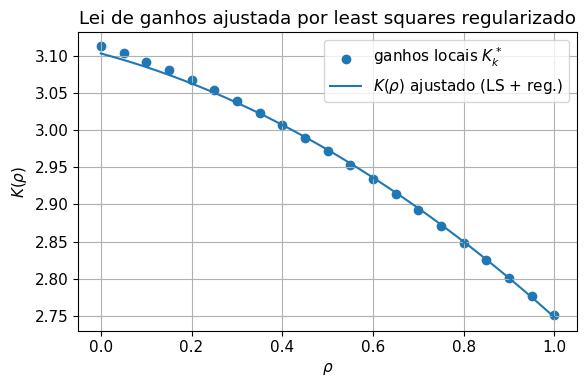

In [14]:
# ---------------------------------------------------------------------------
# 3.4 – Ajuste de K(ρ) via mínimos quadrados regularizado
# ---------------------------------------------------------------------------

def design_matrix_poly(rho_values: np.ndarray, degree: int) -> np.ndarray:
    """
    Constrói a matriz de regressão Φ para um polinômio em ρ de dado grau.

    Para cada valor ρ_i, a linha correspondente em Φ é:

        [1, ρ_i, ρ_i^2, ..., ρ_i^degree]

    rho_values : vetor 1D com valores de ρ.
    degree     : grau do polinômio.
    return     : matriz Φ de dimensão (N x (degree+1)).
    """
    rho_values = np.asarray(rho_values).reshape(-1, 1)
    # Coluna d = 0 é ρ^0 = 1; depois ρ^1, ρ^2, ..., ρ^degree
    return np.hstack([rho_values**d for d in range(degree + 1)])


# Monta Φ e b a partir dos dados (ρ_k, K*_k)
Phi = design_matrix_poly(rho_fine, degree=POLY_DEGREE)
b = K_star_vec

# Variável de decisão θ (parâmetros da lei K(ρ))
theta = cp.Variable(Phi.shape[1])

# Problema de LS com regularização (ridge)
objective = cp.sum_squares(Phi @ theta - b) + GAMMA_REG * cp.sum_squares(theta)
problem = cp.Problem(cp.Minimize(objective))

# Resolve o QP equivalente usando OSQP
problem.solve(solver=cp.OSQP)

print("\nStatus do problema LS regularizado:", problem.status)
print("θ estimado (parâmetros de K(rho)):", theta.value)

# Avaliar K(ρ) ajustado em uma malha mais densa só para visualização
rho_plot = np.linspace(RHO_MIN, RHO_MAX, 200)
Phi_plot = design_matrix_poly(rho_plot, degree=POLY_DEGREE)
K_fit_plot = Phi_plot @ theta.value

# Avaliar também K(ρ) nos mesmos pontos da grade fina
K_fit_at_nodes = Phi @ theta.value

# Gráfico: ganhos locais vs. lei ajustada
plt.figure()
plt.scatter(rho_fine, K_star_vec, label="ganhos locais $K_k^*$")
plt.plot(rho_plot, K_fit_plot, label="$K(\\rho)$ ajustado (LS + reg.)")
plt.xlabel("$\\rho$")
plt.ylabel("$K(\\rho)$")
plt.title("Lei de ganhos ajustada por least squares regularizado")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## <a id='toc3_5_'></a>[Resultados numéricos da otimização](#toc0_)

Os resultados numéricos podem ser organizados em três conjuntos de dados:

- pontos de operação $ (\rho_k, h_k^\star, u_k^\star) $ obtidos pela rotina de equilíbrio;  
- ganhos locais ideais $ K_k^\star $ gerados pelo LQR em cada ponto da grade;  
- valores de $ K(\rho_k;\hat{\theta}) $ fornecidos pela lei ajustada via mínimos quadrados regularizado.

A Tabela 3.1 resume esses dados, permitindo comparar, ponto a ponto, o ganho local ideal $K_k^\star$ e o ganho previsto pela lei contínua $K(\rho_k;\hat{\theta})$. Observa-se que o erro ponto a ponto é pequeno (da ordem de $10^{-3}$ a $10^{-2}$), o que indica que o polinômio de grau 2 adotado é suficiente para representar a variação de $K$ na faixa de operação escolhida.

A partir da solução do problema de mínimos quadrados regularizado, obtém-se o vetor de parâmetros

$$
\hat{\theta} \approx
\begin{bmatrix}
3{,}1034 \\
-0{,}1637 \\
-0{,}1916
\end{bmatrix},
$$

o que leva à expressão numérica

$$
K(\rho) \approx 3{,}1034 - 0{,}1637\,\rho - 0{,}1916\,\rho^2.
$$

A Figura 3.1 mostra os ganhos locais $K_k^\star$ (pontos) e a curva $K(\rho;\hat{\theta})$ (linha contínua). A curva é monotonicamente decrescente em $\rho$, reproduzindo o comportamento dos ganhos LQR e introduzindo um nível controlado de suavização via termo de regularização $\gamma \lVert \theta \rVert_2^2$.


In [15]:
# ---------------------------------------------------------------------------
# 3.5 – Tabela numérica de resultados e expressão de K(ρ)
# ---------------------------------------------------------------------------

# Monta DataFrame com os principais resultados
data = {
    "rho_k": rho_fine,
    "h_star_k": np.array([h for (_, h, _) in equilibria]),
    "u_star_k": np.array([u for (_, _, u) in equilibria]),
    "K_LQR_k": K_star_vec,
    "K_fit_k": K_fit_at_nodes,
}

df_results = pd.DataFrame(data)

print("\nTabela 3.1 – Pontos de operação e ganhos locais vs. lei ajustada K(rho):\n")
print(df_results.round(4).to_string(index=False))

# Expressão numérica aproximada de K(ρ) (polinômio de grau POLY_DEGREE)
theta_hat = theta.value
poly_terms = " + ".join(
    [
        f"{theta_hat[d]:.4f} * rho^{d}" if d > 0 else f"{theta_hat[d]:.4f}"
        for d in range(POLY_DEGREE + 1)
    ]
)

print("\nLei ajustada de ganhos K(rho) (polinômio de grau", POLY_DEGREE, "):")
print("K(rho) ≈", poly_terms)



Tabela 3.1 – Pontos de operação e ganhos locais vs. lei ajustada K(rho):

 rho_k  h_star_k  u_star_k  K_LQR_k  K_fit_k
  0.00    5.0968       0.5   3.1136   3.1034
  0.05    4.2123       0.5   3.1035   3.0947
  0.10    3.5395       0.5   3.0924   3.0851
  0.15    3.0159       0.5   3.0805   3.0745
  0.20    2.6004       0.5   3.0676   3.0630
  0.25    2.2653       0.5   3.0538   3.0505
  0.30    1.9910       0.5   3.0392   3.0371
  0.35    1.7636       0.5   3.0237   3.0227
  0.40    1.5731       0.5   3.0073   3.0073
  0.45    1.4119       0.5   2.9902   2.9910
  0.50    1.2742       0.5   2.9722   2.9737
  0.55    1.1557       0.5   2.9534   2.9554
  0.60    1.0531       0.5   2.9338   2.9362
  0.65    0.9635       0.5   2.9134   2.9161
  0.70    0.8849       0.5   2.8923   2.8950
  0.75    0.8155       0.5   2.8705   2.8729
  0.80    0.7540       0.5   2.8480   2.8499
  0.85    0.6992       0.5   2.8249   2.8259
  0.90    0.6501       0.5   2.8010   2.8009
  0.95    0.6060       0.

## <a id='toc3_6_'></a>[Seleção automática de pontos de operação](#toc0_)

Até a Seção 3.5, os ganhos ideais $K_k^\star$ foram calculados em uma grade fina

$$
\rho_k \in [\rho_{\min}, \rho_{\max}], \qquad k = 1,\dots,N_{\rho},
$$

e uma lei contínua $K(\rho)$ foi ajustada por mínimos quadrados regularizado utilizando todos esses pontos.

Nesta subseção, o objetivo é dar um passo além: a partir da grade fina, selecionar automaticamente um subconjunto reduzido de pontos de operação, de modo que uma lei de ganhos por partes ainda aproxime bem a curva de referência $K_k^\star$.

A ideia é:

1. usar a grade fina $(\rho_k, K_k^\star)$ como referência ideal;  
2. definir uma tolerância máxima de erro $ \varepsilon_{\max} $ entre a aproximação e os ganhos ideais;  
3. construir uma lei de ganhos por partes $K_{\text{pw}}(\rho)$ (piecewise linear), escolhendo o menor número possível de pontos de quebra em $ \rho $ tal que

$$
\max_k \bigl|K_k^\star - K_{\text{pw}}(\rho_k)\bigr| \le \varepsilon_{\max}.
$$

Nesta implementação, usa-se um algoritmo ganancioso simples:

- começa-se com o primeiro ponto da grade (mais à esquerda em $ \rho $);  
- tenta-se conectar esse ponto diretamente a um ponto cada vez mais distante por um segmento de reta em $K(\rho)$;  
- enquanto o erro máximo entre o segmento e os ganhos ideais $K_k^\star$ dentro do intervalo se mantiver abaixo de $ \varepsilon_{\max} $, o segmento é aceito;  
- quando o erro estoura a tolerância, o segmento anterior é fixado como válido e o próximo ponto de operação passa a ser o novo ponto de partida.

O resultado é um conjunto de pontos de operação selecionados automaticamente,

$$
(\hat{\rho}_0, \hat{K}_0),\; (\hat{\rho}_1, \hat{K}_1),\; \dots,\; (\hat{\rho}_M, \hat{K}_M),
$$

com $\hat{\rho}_0 = \rho_{\min}$, $\hat{\rho}_M = \rho_{\max}$ e $M+1$ pontos no total, definindo uma lei de ganhos por partes linear em $ \rho $. O número de pontos $M+1$ surge como saída do algoritmo, e não é escolhido manualmente.

### <a id='toc3_6_1_'></a>[Resultados numéricos da seleção automática](#toc0_)

Aplicando esse algoritmo ganancioso à curva de ganhos ideais $K_k^\star$ obtida na Seção 3.3, com grade fina de $N_\rho = 21$ pontos em $\rho \in [\rho_{\min},\rho_{\max}]$ e tolerância de erro

$$
\varepsilon_{\max} = 5 \times 10^{-3},
$$

obtém-se automaticamente um conjunto reduzido de apenas 4 pontos de operação:

$$
\hat{\rho} = [0{,}00,\; 0{,}30,\; 0{,}65,\; 1{,}00],
$$

com ganhos associados

$$
K^\star(\hat{\rho}) \approx [3{,}1136,\; 3{,}0392,\; 2{,}9134,\; 2{,}7515].
$$

A lei por partes $K_{\text{pw}}(\rho)$ construída a partir desses quatro pontos atinge um erro máximo, nos nós da grade original, de

$$
\max_k \bigl|K_k^\star - K_{\text{pw}}(\rho_k)\bigr|
\approx 4{,}86 \times 10^{-3},
$$

ou seja, dentro da tolerância especificada. Em outras palavras, uma curva de referência originalmente amostrada em 21 pontos é representada, para fins de implementação, por apenas 4 pontos de operação e 3 segmentos lineares em $ \rho $, com erro controlado em norma infinita.

<div style="text-align:center; margin-top:10px; margin-bottom:10px;">
  <img src="./img/Figure_32.png" style="max-width:75%; border-radius:8px;">
  <div style="color:#B0BEC5; font-size:0.9em; margin-top:4px;">
    Figura 3.2 – Seleção automática de pontos de operação: ganhos ideais $K_k^\star$, lei polinomial $K(\rho)$ e lei por partes $K_{\text{pw}}(\rho)$.
  </div>
</div>



Seleção automática de pontos de operação (lei por partes):
Tolerância máxima de erro EPS_MAX = 0.005
Número total de pontos da grade fina      : 21
Número de pontos selecionados automaticamente: 4

Pontos selecionados (ρ_hat, K*_hat):
ρ = 0.000,  K* =  3.1136
ρ = 0.300,  K* =  3.0392
ρ = 0.650,  K* =  2.9134
ρ = 1.000,  K* =  2.7515

Erro máximo nos nós da grade entre K*_k e K_pw(rho_k): 4.8609e-03


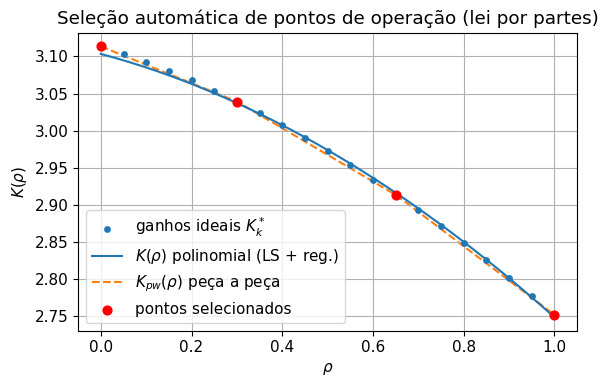

In [16]:
# ---------------------------------------------------------------------------
# 3.6 – Seleção automática de pontos de operação (lei por partes)
# ---------------------------------------------------------------------------

# Tolerância máxima de erro entre K*_k e K_pw(rho_k)
EPS_MAX = 5e-3  # por exemplo, 0.005; pode ser ajustado

def piecewise_linear_greedy(rho_vals: np.ndarray,
                            K_vals: np.ndarray,
                            eps_max: float):
    """
    Seleciona automaticamente um subconjunto de pontos (rho_hat, K_hat)
    usando um algoritmo ganancioso de aproximação por partes.

    Estratégia:
    - Começa no primeiro ponto da grade (índice 0).
    - Para o ponto de partida s, tenta estender um segmento até j > s
      enquanto o erro máximo entre a reta [s,j] e os dados K_vals[s:j+1]
      for <= eps_max.
    - Quando o erro passa da tolerância, fixa o último j válido como
      próximo breakpoint e repete a partir dele.

    Parâmetros
    ----------
    rho_vals : vetor 1D com os valores de ρ da grade fina (ordenados).
    K_vals   : vetor 1D com os ganhos ideais K*_k correspondentes.
    eps_max  : tolerância máxima de erro (norma infinita).

    Retorno
    -------
    rho_hat  : vetor com os ρ selecionados.
    K_hat    : vetor com os ganhos K*_k nesses pontos.
    indices  : índices inteiros da grade original que foram selecionados.
    """
    rho_vals = np.asarray(rho_vals).flatten()
    K_vals = np.asarray(K_vals).flatten()
    N = len(rho_vals)

    selected_indices = [0]  # sempre começa no primeiro ponto (ρ_min)
    s = 0  # índice de início do segmento atual

    while s < N - 1:
        best_j = s + 1  # pelo menos um ponto à frente
        # tenta estender j o máximo possível
        for j in range(s + 1, N):
            # reta entre (rho_s, K_s) e (rho_j, K_j)
            rho_s, K_s = rho_vals[s], K_vals[s]
            rho_j, K_j = rho_vals[j], K_vals[j]

            # evita divisão por zero se rho_s == rho_j (grade deve ser estritamente crescente)
            if rho_j == rho_s:
                continue

            # coeficientes da reta: K_lin(rho) = alpha * rho + beta
            alpha = (K_j - K_s) / (rho_j - rho_s)
            beta = K_s - alpha * rho_s

            # calcula erro máximo no intervalo [s, j]
            rho_segment = rho_vals[s:j + 1]
            K_segment = K_vals[s:j + 1]
            K_lin_segment = alpha * rho_segment + beta
            max_err = np.max(np.abs(K_segment - K_lin_segment))

            if max_err <= eps_max:
                best_j = j  # ainda dentro da tolerância, pode estender
            else:
                break       # passou da tolerância, para de tentar estender

        # fixa o melhor j encontrado para este segmento
        selected_indices.append(best_j)
        s = best_j  # novo segmento começa em best_j

    selected_indices = sorted(set(selected_indices))
    rho_hat = rho_vals[selected_indices]
    K_hat = K_vals[selected_indices]

    return rho_hat, K_hat, selected_indices


# Executa a seleção automática na curva K*_k
rho_hat, K_hat, idx_hat = piecewise_linear_greedy(
    rho_fine, K_star_vec, eps_max=EPS_MAX
)

print("\nSeleção automática de pontos de operação (lei por partes):")
print(f"Tolerância máxima de erro EPS_MAX = {EPS_MAX:.4g}")
print(f"Número total de pontos da grade fina      : {len(rho_fine)}")
print(f"Número de pontos selecionados automaticamente: {len(rho_hat)}\n")

print("Pontos selecionados (ρ_hat, K*_hat):")
for r, K_val in zip(rho_hat, K_hat):
    print(f"ρ = {r:5.3f},  K* = {K_val:7.4f}")

# Reconstrói a lei piecewise linear K_pw(rho) em uma malha densa para visualização
rho_pw_plot = np.linspace(RHO_MIN, RHO_MAX, 400)
K_pw_plot = np.zeros_like(rho_pw_plot)

for i in range(len(rho_hat) - 1):
    r0, r1 = rho_hat[i], rho_hat[i + 1]
    K0, K1 = K_hat[i], K_hat[i + 1]

    # coeficientes da reta no trecho [r0, r1]
    alpha = (K1 - K0) / (r1 - r0)
    beta = K0 - alpha * r0

    # índices de rho_pw_plot que caem nesse intervalo
    mask = (rho_pw_plot >= r0) & (rho_pw_plot <= r1)
    K_pw_plot[mask] = alpha * rho_pw_plot[mask] + beta

# Calcula o erro máximo entre K*_k e K_pw(ρ_k) nos nós originais
# (usando interpolação piecewise linear por trecho)
K_pw_at_nodes = np.zeros_like(K_star_vec)
for i in range(len(rho_hat) - 1):
    r0, r1 = rho_hat[i], rho_hat[i + 1]
    K0, K1 = K_hat[i], K_hat[i + 1]
    alpha = (K1 - K0) / (r1 - r0)
    beta = K0 - alpha * r0

    mask = (rho_fine >= r0) & (rho_fine <= r1)
    K_pw_at_nodes[mask] = alpha * rho_fine[mask] + beta

max_err_nodes = np.max(np.abs(K_star_vec - K_pw_at_nodes))
print(f"\nErro máximo nos nós da grade entre K*_k e K_pw(rho_k): {max_err_nodes:.4e}")

# Gráfico comparando K*_k, K_fit (polinômio) e K_pw (lei por partes)
plt.figure()
plt.scatter(rho_fine, K_star_vec, s=15, label="ganhos ideais $K_k^*$", zorder=3)
plt.plot(rho_plot, K_fit_plot, label="$K(\\rho)$ polinomial (LS + reg.)", zorder=2)
plt.plot(rho_pw_plot, K_pw_plot, "--", label="$K_{pw}(\\rho)$ peça a peça", zorder=1)
plt.scatter(rho_hat, K_hat, c="red", s=40, label="pontos selecionados", zorder=4)
plt.xlabel("$\\rho$")
plt.ylabel("$K(\\rho)$")
plt.title("Seleção automática de pontos de operação (lei por partes)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# <a id='toc4_'></a>[Discussão](#toc0_)

Esta seção discute as principais limitações, escolhas de parâmetros e possíveis generalizações da abordagem de agendamento contínuo de ganhos implementada na Seção 3, agora à luz dos resultados numéricos da Tabela 3.1, das curvas $K(\rho)$ e da lei por partes obtida na Seção 3.6.

Ao longo da solução computacional foram utilizados três tipos principais de resolvedores numéricos:

- solução de equilíbrio não linear via  
  <span style="color:#FFB74D;">`scipy.optimize.fsolve`</span> (equações $f(h^\star,u^\star,\rho)=0$);  
- solução de LQR contínuo via equação algébrica de Riccati com  
  <span style="color:#FFB74D;">`scipy.linalg.solve_continuous_are`</span>;  
- solução do problema de mínimos quadrados regularizado (formulado como QP convexo) via  
  <span style="color:#FFB74D;">`cvxpy` + solver OSQP</span>.

A seleção automática de pontos de operação da Seção 3.6 é feita por um algoritmo ganancioso puramente algébrico, sem chamar solvers externos: o código percorre a grade de $ \rho $ e decide localmente onde inserir quebras de segmento.

## <a id='toc4_1_'></a>[Limitações do modelo e da linearização](#toc0_)

O ponto de partida é o próprio modelo não linear do tanque e a forma como $ \rho $ entra na dinâmica:

- a planta usada é um tanque com saída por gravidade, com $ a(\rho) $ modelada como função afim entre dois extremos $ a_0 $ e $ a_1 $;  
- a dependência em $ \rho $ é introduzida via normalização
  $$
  \beta(\rho) = \frac{\rho - \rho_{\min}}{\rho_{\max} - \rho_{\min}}, \qquad
  a(\rho) = a_0 + \beta(\rho)\,(a_1 - a_0),
  $$
  o que é conveniente para código, mas ainda é uma aproximação simples;  
- a linearização em torno de cada ponto $ (h_k^\star,u_k^\star,\rho_k) $ é de primeira ordem e é válida apenas em uma vizinhança local.

Do ponto de vista de otimização, isso significa que cada problema quadrático resolvido pelo LQR usa restrições de igualdade lineares apenas aproximadas da planta. Se o sistema operar muito longe dos níveis $ h_k^\star $ e da faixa de $ \rho $ em que a grade foi construída, as matrizes $ (A_k,B_k) $ deixam de representar bem a dinâmica real. Nesse caso, o ganho $ K_k^\star $ obtido pelo LQR é ótimo para um modelo que já está desalinhado da planta.

Na prática, isso pode levar a:

- perda de desempenho quando o nível $ h(t) $ se afasta demais dos pontos de equilíbrio;  
- sensibilidade a dinâmicas não modeladas (atrasos, ruídos, saturações internas);  
- risco de instabilidade se $ \rho(t) $ variar rápido demais e o modelo linear usado na síntese já não for representativo.

A Tabela 3.1 mostra uma variação suave de $ h_k^\star $ e de $ K_k^\star $ em $ \rho_k \in [\rho_{\min},\rho_{\max}] $, o que indica que, para essa faixa específica, a aproximação funciona bem. Mas nada garante comportamento semelhante fora do intervalo de projeto ou para trajetórias de $ \rho(t) $ mais agressivas.

## <a id='toc4_2_'></a>[Escolha dos pesos e da regularização](#toc0_)

Os pesos $ q $ e $ r $ usados no LQR e o parâmetro de regularização $ \gamma $ no problema de mínimos quadrados regularizado são responsáveis por grande parte da forma final de $ K(\rho) $.

No LQR, o funcional

$$
J_k = \int_0^\infty \left( q\,\tilde{h}(t)^2 + r\,\tilde{u}(t)^2 \right)\,dt
$$

define o compromisso entre:

- rastrear o nível de referência (via $ q $);  
- limitar o esforço de controle (via $ r $).

Na Tabela 3.1, os ganhos $ K_k^\star $ formam uma curva monotonicamente decrescente, com variação moderada entre $ \rho_{\min} $ e $ \rho_{\max} $. Se $ q $ fosse muito maior (ou $ r $ muito menor), a tendência seria produzir ganhos mais altos, possivelmente com variações mais acentuadas em $ \rho $, o que poderia exigir um polinômio de grau maior ou um $ \gamma $ mais forte para manter a lei ajustada suave.

Na etapa de ajuste, o problema

$$
\min_{\theta} \;\; \lVert \Phi \theta - b \rVert_2^2 + \gamma \lVert \theta \rVert_2^2
$$

introduz o trade-off clássico:

- $ \gamma $ pequeno: $ K(\rho) $ fica muito próximo dos pontos $ K_k^\star $, mas pode oscilar mais se o modelo polinomial tentar perseguir variações locais de modelo ou numéricas;  
- $ \gamma $ grande: a solução tende a um polinômio de norma pequena (curva mais reta), sacrificando parte da fidelidade em relação aos ganhos locais.

Nos resultados mostrados, um $ \gamma $ moderado produz coeficientes

$$
\hat{\theta} \approx
\begin{bmatrix}
3{,}1034 \\
-0{,}1637 \\
-0{,}1916
\end{bmatrix},
$$

com erro ponto a ponto pequeno entre $ K_k^\star $ e $ K(\rho_k;\hat{\theta}) $. Isso indica que, para a faixa de $ \rho $ e os pesos LQR escolhidos, o grau 2 e o valor de $ \gamma $ adotados são suficientes. Em outras faixas de operação, seria natural repetir o experimento variando $ q $, $ r $, o grau do polinômio e $ \gamma $ para avaliar a sensibilidade.

Do ponto de vista de solvers, a etapa de LQR usa diretamente `solve_continuous_are`, que resolve a equação de Riccati de forma determinística e rápida para dimensões pequenas. Já o problema em $ \theta $ é entregue ao OSQP via `cvxpy`, explorando a estrutura de QP convexo com Hessiana definida positiva.

## <a id='toc4_3_'></a>[Casos especiais e situações críticas](#toc0_)

Mesmo com a boa aderência observada na Tabela 3.1, alguns cenários exigem cuidado:

- extrapolação em $ \rho $: a lei $ K(\rho) $ foi ajustada em $ [\rho_{\min},\rho_{\max}] $. Se, em operação, $ \rho $ sair dessa faixa, o polinômio passa a extrapolar. Nada garante que os valores resultantes ainda sejam adequados do ponto de vista de estabilidade ou desempenho;  
- variações rápidas de $ \rho(t) $: a construção assume que $ \rho(t) $ muda de forma relativamente lenta, permitindo que o sistema acompanhe a transição de ganho. Se $ \rho(t) $ saltar rapidamente entre valores, o sistema pode ver um chattering de ganho ou transientes fortes, especialmente em regiões em que a linearização é menos precisa;  
- saturação de atuador: o LQR local não impõe limites em $ u(t) $. A lei $ \tilde{u}(t) = -K(\rho)\,\tilde{h}(t) $ pode sugerir comandos acima da capacidade real do atuador, o que, na prática, exige saturação explícita, mecanismos de anti-windup ou uma reformulação em QP com restrições em $ u $ e $ \Delta u $;  
- ganhos pouco físicos: embora o caso estudado produza $ K(\rho) $ positivo e monotonicamente decrescente, nada impede que, em outro cenário (faixa diferente de $ \rho $, grau maior, ruído nos dados), o ajuste produza ganhos negativos ou muito grandes em certas regiões. Uma maneira de lidar com isso seria impor desigualdades do tipo
  $$
  K(\rho_k;\theta) \ge K_{\min}, \qquad K(\rho_k;\theta) \le K_{\max},
  $$
  nos nós da grade, transformando o problema em um QP com restrições em $ \theta $ e resolvendo-o novamente via OSQP.

## <a id='toc4_4_'></a>[Generalizações dentro da mesma estrutura](#toc0_)

Mesmo com um exemplo simples, a estrutura construída na Seção 3 é suficientemente geral para acomodar variações que ainda cabem dentro do escopo deste trabalho, sem mudar o tipo de problemas de otimização resolvidos.

- sistemas de maior ordem  
  Para modelos com estados $x(t) \in \mathbb{R}^n$, o procedimento permanece o mesmo: linearização em torno de pontos de operação, solução de LQR via equação de Riccati e construção de uma lei de ganhos $K(\rho)$. A diferença é que $K(\rho)$ passa a ser vetorial (ou matricial), e o ajuste por mínimos quadrados regularizado é feito componente a componente ou empacotando todos os ganhos em um único vetor $b$ na formulação  
  $$
  \min_{\theta} \;\; \lVert \Phi \theta - b \rVert_2^2 + \gamma \lVert \theta \rVert_2^2.
  $$

- parametrizações alternativas de $K(\rho)$  
  Em vez de um polinômio de grau fixo, pode-se empregar funções afins por partes em $\rho$, como na Seção 3.6. Nesse caso, os parâmetros deixam de ser coeficientes polinomiais e passam a ser valores de ganho em nós selecionados. Ainda assim, o ajuste continua baseado em erros quadráticos entre uma curva de referência $K_k^\star$ e uma aproximação $K(\rho)$, e pode ser escrito como um problema de programação quadrática com estrutura similar.

- inclusão explícita de restrições em $u$ e $\Delta u$  
  Embora o LQR usado aqui não imponha saturações, a mesma dinâmica linearizada
  $$
  x_{k+1} = A_{d,k} x_k + B_{d,k} u_k
  $$
  pode ser inserida em um problema de horizonte finito com custo quadrático em $(x_k,u_k)$ e restrições lineares do tipo
  $$
  u_{\min} \le u_k \le u_{\max}, \qquad
  \Delta u_{\min} \le u_k - u_{k-1} \le \Delta u_{\max},
  $$
  resultando em um QP convexo que pode ser resolvido pelo mesmo ambiente `cvxpy` com OSQP. A lei de ganhos obtida nesse cenário continua sendo uma solução de um problema de otimização quadrática com restrições de igualdade (dinâmica) e desigualdade (limites físicos).

- combinação entre lei polinomial e lei por partes  
  A comparação numérica da Seção 4.5 mostra que a lei polinomial global $K(\rho;\hat{\theta})$ e a lei por partes $K_{\text{pw}}(\rho)$ são duas formas distintas de resumir a mesma curva LQR $K_k^\star$. Dependendo do critério adotado (erro máximo permitido, número de pontos de operação, facilidade de implementação), é possível escolher a parametrização mais adequada mantendo exatamente a mesma espinha dorsal de modelagem: dinâmica linearizada, custo quadrático e solução via LQR, least squares regularizado e aproximação por segmentos lineares em $\rho$.

Em todas essas variações internas, os blocos fundamentais permanecem os mesmos: restrições de igualdade associadas à dinâmica, desigualdades lineares representando limites físicos e funções objetivo quadráticas medindo erro, esforço e suavidade. A abordagem de agendamento de ganhos usada ao longo do texto é, portanto, um exemplo concreto de como problemas de controle podem ser estruturados diretamente em termos de otimização convexa.

## <a id='toc4_5_'></a>[Comparação numérica entre as leis de ganho e solvers utilizados](#toc0_)

Para consolidar a análise, é útil comparar quantitativamente:

- a curva de ganhos ideais $ K_k^\star $ obtida via LQR em cada ponto da grade (Seção 3.3);  
- a lei polinomial global $ K(\rho;\hat{\theta}) $ ajustada por mínimos quadrados regularizado (Seção 3.4);  
- a lei por partes $ K_{\text{pw}}(\rho) $ construída na Seção 3.6 a partir da seleção automática de pontos.

Uma forma simples de comparação é calcular, nos nós da grade $ \rho_k $:

- o erro máximo (norma infinita)  
  $$
  e_{\max}^{\text{poly}} = \max_k \bigl| K_k^\star - K(\rho_k;\hat{\theta}) \bigr|, \qquad
  e_{\max}^{\text{pw}} = \max_k \bigl| K_k^\star - K_{\text{pw}}(\rho_k) \bigr|;
  $$
- o erro quadrático médio (RMS)  
  $$
  e_{\text{RMS}}^{\text{poly}} = \sqrt{\frac{1}{N_\rho}\sum_k \bigl( K_k^\star - K(\rho_k;\hat{\theta}) \bigr)^2},
  $$
  $$
  e_{\text{RMS}}^{\text{pw}} = \sqrt{\frac{1}{N_\rho}\sum_k \bigl( K_k^\star - K_{\text{pw}}(\rho_k) \bigr)^2}.
  $$

Aplicando essas métricas aos resultados da Seção 3, com $N_\rho = 21$ pontos na grade fina, obtém-se:

- lei polinomial global $K(\rho;\hat{\theta})$ (least squares regularizado, resolvido via `cvxpy` com OSQP):  
  $$
  e_{\max}^{\text{poly}} \approx 1{,}02 \times 10^{-2}, \qquad
  e_{\text{RMS}}^{\text{poly}} \approx 4{,}13 \times 10^{-3};
  $$

- lei por partes $K_{\text{pw}}(\rho)$ (seleção automática gananciosa, sem solver externo):  
  $$
  e_{\max}^{\text{pw}} \approx 4{,}86 \times 10^{-3}, \qquad
  e_{\text{RMS}}^{\text{pw}} \approx 3{,}13 \times 10^{-3},
  $$
  usando apenas 4 pontos de operação selecionados a partir da grade original.

Esses números mostram, de forma concreta, o compromisso entre as diferentes etapas de otimização: o LQR local fornece a curva de referência $K_k^\star$ (via `solve_continuous_are`), o ajuste polinomial com OSQP produz uma aproximação global suave, enquanto a lei por partes $K_{\text{pw}}(\rho)$ consegue, com um número bem menor de pontos de operação, reduzir o erro máximo em relação aos ganhos ideais. A escolha entre usar a lei polinomial ou a lei por partes passa a ser uma decisão de projeto entre simplicidade da parametrização e número de controladores locais a serem implementados.


In [17]:
# ---------------------------------------------------------------------------
# 4.5 – Comparação numérica entre K*_k, K(ρ;θ̂) e K_pw(ρ)
# ---------------------------------------------------------------------------
# Pré-requisitos (definidos nas seções anteriores):
# - rho_fine    : vetor 1D com a grade fina de ρ (N_RHO_FINE nós)
# - K_star_vec  : vetor 1D com os ganhos ideais K*_k (LQR) em cada ρ_k
# - Phi         : matriz de regressão avaliada em rho_fine (Seção 3.4)
# - theta       : solução do problema de mínimos quadrados regularizado
#                 (cvxpy + OSQP), contendo θ̂
# - K_pw_at_nodes : vetor 1D com K_pw(ρ_k) da Seção 3.6
# - rho_hat, K_hat: pontos selecionados automaticamente na Seção 3.6

# Se necessário, reconstroi K(ρ_k;θ̂) nos nós
K_fit_at_nodes = Phi @ theta.value  # mesma dimensão que K_star_vec

# Erros da lei polinomial global (LS + regularização)
err_poly = K_star_vec - K_fit_at_nodes
max_err_poly = np.max(np.abs(err_poly))
rms_err_poly = np.sqrt(np.mean(err_poly**2))

# Erros da lei por partes K_pw(ρ)
err_pw = K_star_vec - K_pw_at_nodes
max_err_pw = np.max(np.abs(err_pw))
rms_err_pw = np.sqrt(np.mean(err_pw**2))

print("\nComparação numérica entre as leis de ganho:")
print("---------------------------------------------------------")
print(f"Número de pontos da grade fina (N_rho) : {len(rho_fine)}")
print(f"Número de pontos selecionados (piecewise): {len(rho_hat)}")
print("---------------------------------------------------------")
print("Lei polinomial global  K(rho; θ̂)  (LS + regularização):")
print(f"  Erro máximo (∞-norm) : {max_err_poly:.4e}")
print(f"  Erro RMS             : {rms_err_poly:.4e}")
print("---------------------------------------------------------")
print("Lei por partes K_pw(rho) (seleção automática gananciosa):")
print(f"  Erro máximo (∞-norm) : {max_err_pw:.4e}")
print(f"  Erro RMS             : {rms_err_pw:.4e}")
print("---------------------------------------------------------")
print("Solvers utilizados no fluxo completo:")
print("  - Equilíbrios não lineares  : scipy.optimize.fsolve")
print("  - LQR contínuo (Riccati)    : scipy.linalg.solve_continuous_are")
print("  - LS regularizado (QP conv.) : cvxpy + solver OSQP")
print("  - Lei por partes K_pw(rho)  : algoritmo ganancioso (loops em Python)")



Comparação numérica entre as leis de ganho:
---------------------------------------------------------
Número de pontos da grade fina (N_rho) : 21
Número de pontos selecionados (piecewise): 4
---------------------------------------------------------
Lei polinomial global  K(rho; θ̂)  (LS + regularização):
  Erro máximo (∞-norm) : 1.0204e-02
  Erro RMS             : 4.1261e-03
---------------------------------------------------------
Lei por partes K_pw(rho) (seleção automática gananciosa):
  Erro máximo (∞-norm) : 4.8609e-03
  Erro RMS             : 3.1302e-03
---------------------------------------------------------
Solvers utilizados no fluxo completo:
  - Equilíbrios não lineares  : scipy.optimize.fsolve
  - LQR contínuo (Riccati)    : scipy.linalg.solve_continuous_are
  - LS regularizado (QP conv.) : cvxpy + solver OSQP
  - Lei por partes K_pw(rho)  : algoritmo ganancioso (loops em Python)
